# 作业3：NumPy、Matplotlib 与 pandas

In [1]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080302
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] HRRR
[学号] 20244080302
[机器指纹] c203dca07a7d4af6
[RUN_ID] 20244080302-c203dca07a7d4af6


围绕半圆定律

随机矩阵理论研究随机矩阵的性质。对于下述随机对称矩阵，随着矩阵阶数 $n$ 增大，其特征值的分布趋近于半圆定律。半圆密度为

$$
f(x) =
\begin{cases}
\dfrac{1}{2\pi}\sqrt{4 - x^2}, & |x| \le 2, \\[6pt]
0, & |x| > 2.
\end{cases}
$$

构造 $n \times n$ 的对称随机矩阵 $Z$：对所有 $1 \le i \le j \le n$，独立地从均值为 $0$、方差为 $1/n$ 的正态分布抽取 $Z_{ij}$，再令 $Z_{ji} = Z_{ij}$。这样的矩阵称为 **Wigner 矩阵**。其特征值的标准化直方图会随 $n$ 增大而逐渐接近上述密度曲线。

1. 编写 `wigner_density(x)`，接收一个整数或浮点数，返回半圆密度在 $x$ 处的值，返回值为浮点数。不需要检查输入类型；函数应同时适用于 Python 和 NumPy 的整数、浮点数。计算平方根时使用 `numpy.sqrt`，不要使用 `math.sqrt`。

2. 编写 `generate_wigner(n)`，接收正整数 $n$，返回一个随机生成的 $n \times n$ Wigner 矩阵，可以使用 NumPy 的二维数组或矩阵表示。若输入不是整数或不是正数，应抛出合适的异常。

3. 编写 `get_spectrum(matrix)`，接收 NumPy 矩阵或二维 NumPy 数组，返回包含其全部特征值的 NumPy 数组，按非递减顺序排列。本函数不需要检查输入类型。

4. 画一张包含四个纵向排列子图的图。对 $n = 100, 200, 500, 1000$，每个子图分别用蓝色、标准化的直方图展示随机 $n \times n$ Wigner 矩阵的特征值，并叠加红色的半圆密度曲线。根据图形说明：$n$ 大约达到多少时，半圆密度能较好地拟合特征值分布？使用 Kolmogorov–Smirnov 检验作更严格的比较是可选任务。特征值计算可能较慢，尤其是远大于 $1000$ 阶的矩阵。

In [10]:
import numpy as np
def wigner_density(x):
    """半圆密度：|x| <= 2 时返回 sqrt(4 - x^2) / (2 * pi)，否则返回 0。"""
    if abs(x) > 2:
        return 0.0
    return float(np.sqrt(4 - x ** 2) / (2 * np.pi))


print(wigner_density(0), wigner_density(2), wigner_density(np.int64(1)), wigner_density(3))


0.3183098861837907 0.0 0.27566444771089604 0.0


In [12]:
def generate_wigner(n):
    """生成 n x n 的 Wigner 矩阵：上三角（含对角线）元素 ~ N(0, 1/n)，再对称化。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")
    sigma = 1.0 / np.sqrt(n)
    z = np.triu(np.random.normal(0.0, sigma, size=(n, n)))
    return z + np.triu(z, 1).T


w = generate_wigner(5)
print(w.shape, "对称:", np.allclose(w, w.T))
print(np.round(w, 3))


(5, 5) 对称: True
[[-0.141  0.388 -0.022 -0.01  -0.774]
 [ 0.388 -0.103 -0.361  0.065  0.335]
 [-0.022 -0.361  0.327 -0.143  0.089]
 [-0.01   0.065 -0.143 -0.618 -0.396]
 [-0.774  0.335  0.089 -0.396  0.374]]


In [13]:
def get_spectrum(matrix):
    """返回矩阵的全部特征值，按非递减（升序）排列。"""
    eigenvalues = np.linalg.eigvals(np.asarray(matrix))
    return np.sort(np.real(eigenvalues))


print(get_spectrum(np.array([[2.0, 1.0], [1.0, 2.0]])))


[1. 3.]


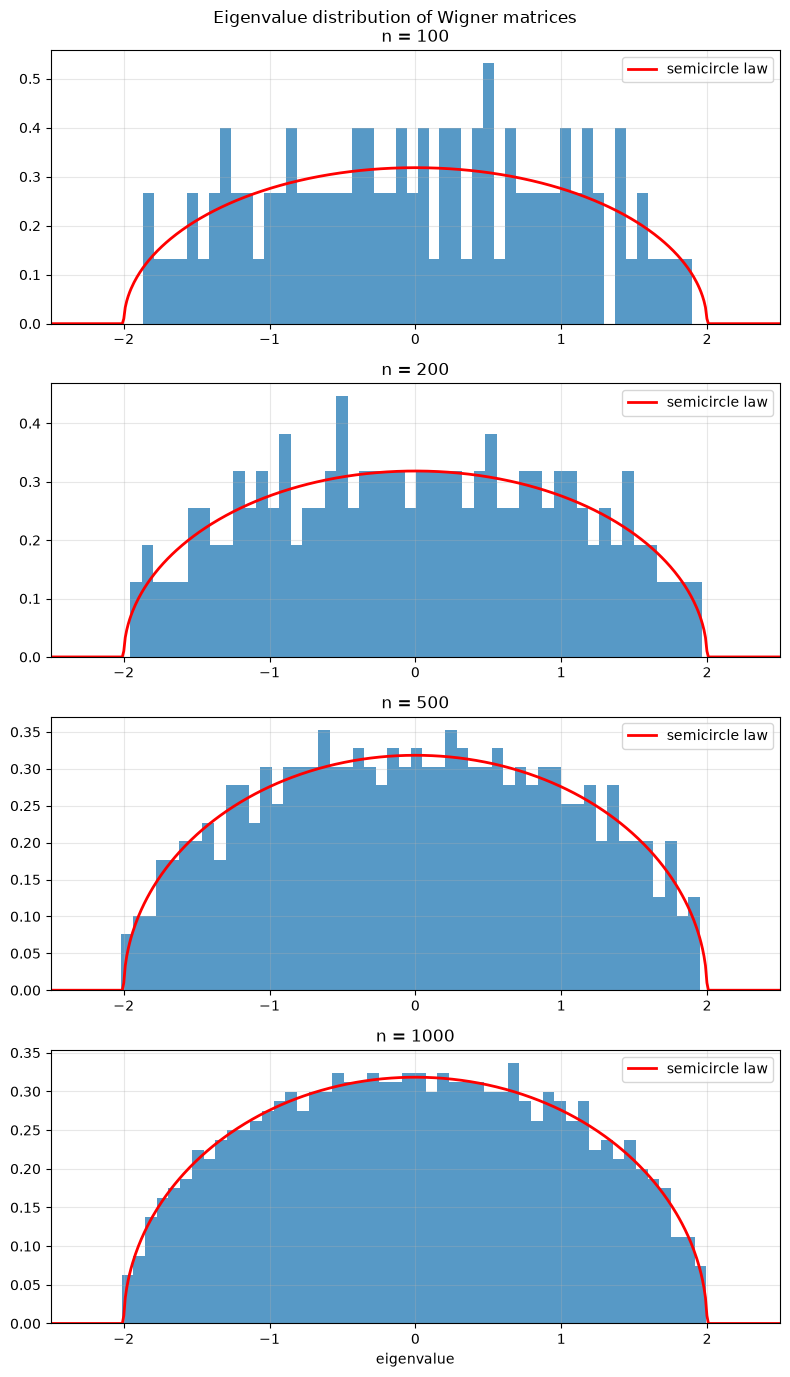

In [14]:
import matplotlib.pyplot as plt
ns = [100, 200, 500, 1000]
grid = np.linspace(-2.5, 2.5, 500)
density = np.array([wigner_density(x) for x in grid])

fig, axes = plt.subplots(len(ns), 1, figsize=(8, 14))
for ax, n in zip(axes, ns):
    spectrum = get_spectrum(generate_wigner(n))
    ax.hist(spectrum, bins=50, density=True, color="tab:blue", alpha=0.75)
    ax.plot(grid, density, color="red", linewidth=2, label="semicircle law")
    ax.set_title(f"n = {n}")
    ax.set_xlim(-2.5, 2.5)
    ax.grid(alpha=0.3)
    ax.legend()
axes[-1].set_xlabel("eigenvalue")
fig.suptitle("Eigenvalue distribution of Wigner matrices")
fig.tight_layout()
plt.show()


In [15]:
from scipy import stats


def semicircle_cdf(x):
    """半圆定律的分布函数 F(x)。"""
    x = np.asarray(x, dtype=float)
    xc = np.clip(x, -2.0, 2.0)
    cdf = (
        0.5
        + xc * np.sqrt(np.maximum(4.0 - xc ** 2, 0.0)) / (4 * np.pi)
        + np.arcsin(xc / 2.0) / np.pi
    )
    return np.where(x < -2.0, 0.0, np.where(x > 2.0, 1.0, cdf))


for n in [100, 200, 500, 1000]:
    spectrum = get_spectrum(generate_wigner(n))
    result = stats.kstest(spectrum, semicircle_cdf)
    print(f"n = {n:4d}: KS statistic = {result.statistic:.4f}")


n =  100: KS statistic = 0.0204
n =  200: KS statistic = 0.0202
n =  500: KS statistic = 0.0049
n = 1000: KS statistic = 0.0029


康威生命游戏（Conway's Game of Life）

康威生命游戏是一种经典的二维细胞自动机，由一个 **0/1 数组**（不一定是方阵）描述：数字为 1 表示该位置有一个细胞，0 表示没有细胞。每轮演化中，每个格子的下一状态由它周围 8 个邻居决定：

- 如果某个位置当前的存活状态为 0，而它有 3 个邻居，则下一轮该位置变为 1，否则保持为 0（繁殖）。
- 如果某个位置当前的存活状态为 1，而它有 2 或 3 个邻居，则下一轮保持为 1，否则变为 0（邻居过少会孤单死亡，过多会因拥挤死亡）。

数组边界之外的格子都视为死细胞（存活状态为 0），因此可以**先在数组四周补一圈 0**，这样每个真实细胞的邻居数量都能直接算出来，边界处的规则也有明确定义。

编写以下函数：

1. 编写 `is_valid_board(board)`：传入一个参数，判断它是否是合法的棋盘——一个元素只为 $0$ 或 $1$ 的**二维** NumPy 数组。不满足条件时返回 `False`，否则返回 `True`。

2. 编写 `gol_step(board)`：接收一个棋盘（NumPy 数组），计算它在生命游戏中演化一步后的结果并返回，返回值应为同样大小的 NumPy 数组。函数不应修改原棋盘数组。若输入不是合法棋盘，应抛出合适的异常。计算某个细胞的下一状态时，必须使用原棋盘中邻居的状态，而不是已经被更新过的部分棋盘。

3. 编写 `draw_gol_board(board)`：接收一个二维棋盘，用 `matplotlib.pyplot` 将它画成图像，其中存活细胞为黑色、死细胞为白色。图中不显示网格线、坐标轴标签或坐标轴刻度。


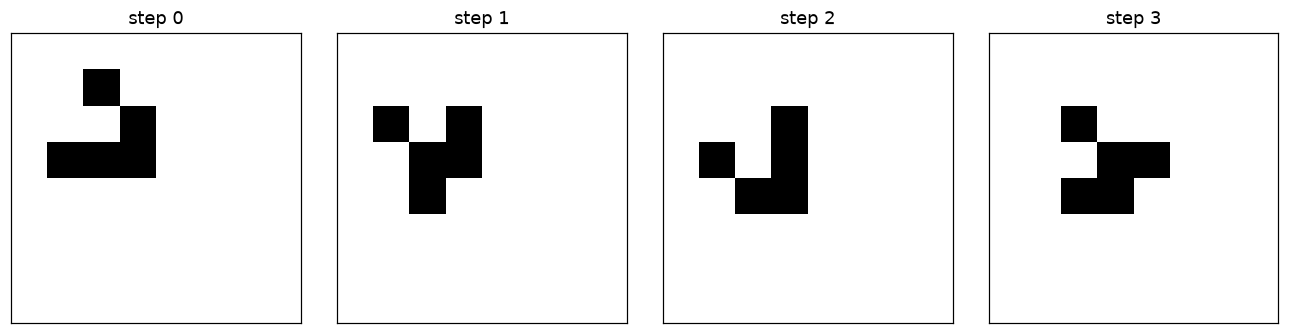

In [16]:
import numpy as np
import matplotlib.pyplot as plt


def is_valid_board(board):
    """判断 board 是否为元素全为 0/1 的二维 NumPy 数组。"""
    if not isinstance(board, np.ndarray) or board.ndim != 2:
        return False
    return bool(np.isin(board, (0, 1)).all())


def gol_step(board):
    """返回生命游戏演化一步后的新棋盘（不修改原棋盘）。"""
    if not is_valid_board(board):
        raise ValueError("无效的棋盘：需要元素为 0/1 的二维 NumPy 数组")

    cells = np.asarray(board).astype(int)
    n, m = cells.shape
    # 四周补一圈 0，边界外即为死细胞
    padded = np.pad(cells, 1, mode="constant", constant_values=0)
    neighbors = np.zeros((n, m), dtype=int)
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            neighbors += padded[1 + di: 1 + di + n, 1 + dj: 1 + dj + m]

    next_board = (neighbors == 3) | ((cells == 1) & (neighbors == 2))
    return next_board.astype(int)


def draw_gol_board(board):
    """将棋盘画成黑白图像：存活细胞为黑色，死细胞为白色。"""
    plt.imshow(np.asarray(board), cmap="gray_r", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])


# 演示：滑翔机（每 4 步沿对角线平移一格）
glider = np.array([
    [0, 1, 0],
    [0, 0, 1],
    [1, 1, 1],
])
board = np.zeros((8, 8), dtype=int)
board[1:4, 1:4] = glider

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for step, ax in enumerate(axes):
    plt.sca(ax)
    draw_gol_board(board)
    ax.set_title(f"step {step}")
    board = gol_step(board)
fig.tight_layout()


## 使用 pandas DataFrame

本题练习读取、修改和保存 DataFrame，以及按组汇总数据。

1. 下载 [iris.csv](https://www.kaggle.com/datasets/gradylynn/iris-csv)。使用 pandas 将它读入为 DataFrame；CSV 的第一行是列标题。回答：数据集有多少个数据点？每列是什么数据类型？列名是什么？数据中有多少种花卉？列名对应花卉种类，以及花瓣长度、花瓣宽度、萼片长度和萼片宽度四项测量。

2. 已知数据的第 35 个和第 38 个数据行有误（不计列标题）。将第 35 行改为

   ```text
   4.9,3.1,1.5,0.2,"setosa"
   ```

   其中原文件的第四项测量有误；将第 38 行改为

   ```text
   4.9,3.6,1.4,0.1,"setosa"
   ```

   其中原文件的第二、三项测量有误。请在 DataFrame 中完成修改，并检查修改后的两行。若采用从 0 开始的默认行索引，这两行的索引分别是 34 和 37。

3. 添加两列新特征：`Petal.Ratio` 为花瓣长度除以花瓣宽度；`Sepal.Ratio` 为萼片长度除以萼片宽度。

4. 将更正并扩展后的 DataFrame 保存为 `iris_corrected.csv`，并随作业提交。

5. 按花卉种类分组，分别计算 `Petal.Ratio` 和 `Sepal.Ratio` 的平均值、中位数、最小值、最大值和标准差。使用合适的 `groupby()` 或聚合操作一次获得这些结果。


In [1]:
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

CSV_PATH = "archive/Iris.csv"
CORRECTED_PATH = "iris_corrected.csv"
SPECIES = "Species"
MEASUREMENTS = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

# 第一行是列标题；Id 从 1 开始，减 1 后作为从 0 开始的行索引，使第 35、38 行的索引为 34、37
df = pd.read_csv(CSV_PATH, index_col="Id")
df.index = df.index - 1
df.index.name = None

# 1. 数据集概况（Species 取值为 Iris-setosa / Iris-versicolor / Iris-virginica）
print("数据点个数:", len(df))
print("\n列名:", list(df.columns))
print("\n每列数据类型:")
print(df.dtypes)
print("\n花卉种类数:", df[SPECIES].nunique())
print(df[SPECIES].value_counts())

# 2. 更正第 35、38 个数据行（行索引 34、37）
df.loc[34, MEASUREMENTS] = [4.9, 3.1, 1.5, 0.2]
df.loc[34, SPECIES] = "Iris-setosa"
df.loc[37, MEASUREMENTS] = [4.9, 3.6, 1.4, 0.1]
df.loc[37, SPECIES] = "Iris-setosa"
print("\n更正后的第 35、38 行:")
print(df.loc[[34, 37]])

# 3. 添加两个新特征
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]
print("\n添加新特征后的前 5 行:")
print(df.head())

# 4. 保存结果（保留 0~149 的行索引，便于对照第 35、38 行）
df.to_csv(CORRECTED_PATH)
print("\n已保存到:", CORRECTED_PATH)

# 5. 按种类分组汇总
summary = df.groupby(SPECIES)[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print("\n按花卉种类分组的统计量:")
print(summary)


数据点个数: 150

列名: ['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

每列数据类型:
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object

花卉种类数: 3
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

更正后的第 35、38 行:
    SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34            4.9           3.1            1.5           0.2  Iris-setosa
37            4.9           3.6            1.4           0.1  Iris-setosa

添加新特征后的前 5 行:
   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  Petal.Ratio  Sepal.Ratio
0            5.1           3.5            1.4           0.2  Iris-setosa          7.0     1.457143
1            4.9           3.0            1.4           0.2  Iris-setosa          7.0     1.633333
2            4.7           3.2            1.3           0.2  Iris-setosa          6.5     1.468750